# DBP metric computation walkthrough

This notebook follows one video through the metric pipeline. It shows the decoded evidence, the formula, and the resulting value for each metric.

The calculations intentionally mirror the production definitions while remaining readable. They describe bounded samples of the encoded video—not ground-truth physical properties of the original scene.

In [1]:
from fractions import Fraction
from pathlib import Path
import json
import re
import subprocess

import cv2
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

VIDEO_PATH = Path("data/nsd_subj01.mp4")
assert VIDEO_PATH.is_file(), f"Missing demo video: {VIDEO_PATH.resolve()}"

def run(command, *, check=True):
    result = subprocess.run(command, capture_output=True, check=check)
    return result

VIDEO_PATH.resolve()

PosixPath('/Users/lobennett/grants/dbp/.worktrees/metric-computation-walkthrough-v1/notebooks/data/nsd_subj01.mp4')

In [2]:
display(HTML(
    f'<video controls width="480" src="{VIDEO_PATH.as_posix()}">'
    "Your notebook viewer cannot play this video.</video>"
))

## 1. Container and stream metrics

One `ffprobe` call reads properties stored in the media container:

- **Duration**: reported container duration in seconds.
- **Width and height**: encoded dimensions of the first video stream.
- **Frame rate**: `avg_frame_rate` converted from a fraction to frames per second.
- **Audio present**: whether the file contains an audio stream.

These values do not require frame sampling.

In [3]:
probe = run([
    "ffprobe", "-v", "error",
    "-show_entries", "format=duration:stream=codec_type,width,height,avg_frame_rate",
    "-of", "json", str(VIDEO_PATH),
])
probe_data = json.loads(probe.stdout)
video_stream = next(stream for stream in probe_data["streams"] if stream["codec_type"] == "video")

duration_seconds = float(probe_data["format"]["duration"])
width_px = int(video_stream["width"])
height_px = int(video_stream["height"])
frame_rate_fps = float(Fraction(video_stream["avg_frame_rate"]))
audio_track_present = any(stream["codec_type"] == "audio" for stream in probe_data["streams"])

stream_metrics = {
    "duration_seconds": duration_seconds,
    "width_px": width_px,
    "height_px": height_px,
    "frame_rate_fps": frame_rate_fps,
    "audio_track_present": audio_track_present,
}
stream_metrics

{'duration_seconds': 10.0,
 'width_px': 800,
 'height_px': 800,
 'frame_rate_fps': 4.0,
 'audio_track_present': False}

## 2. Shared sampled-frame representation

Brightness, contrast, colorfulness, and temporal change use the same bounded sample:

1. reset timestamps to zero;
2. inspect at most the first 60 seconds;
3. retain distinct source frames at least 0.5 seconds apart (at most 2 samples/second);
4. stop after 120 frames;
5. area-resize each frame to 160 × 160 and decode as 8-bit RGB.

The resize stretches the aspect ratio. The numbers therefore describe this standardized representation, which makes clips comparable and keeps computation bounded.

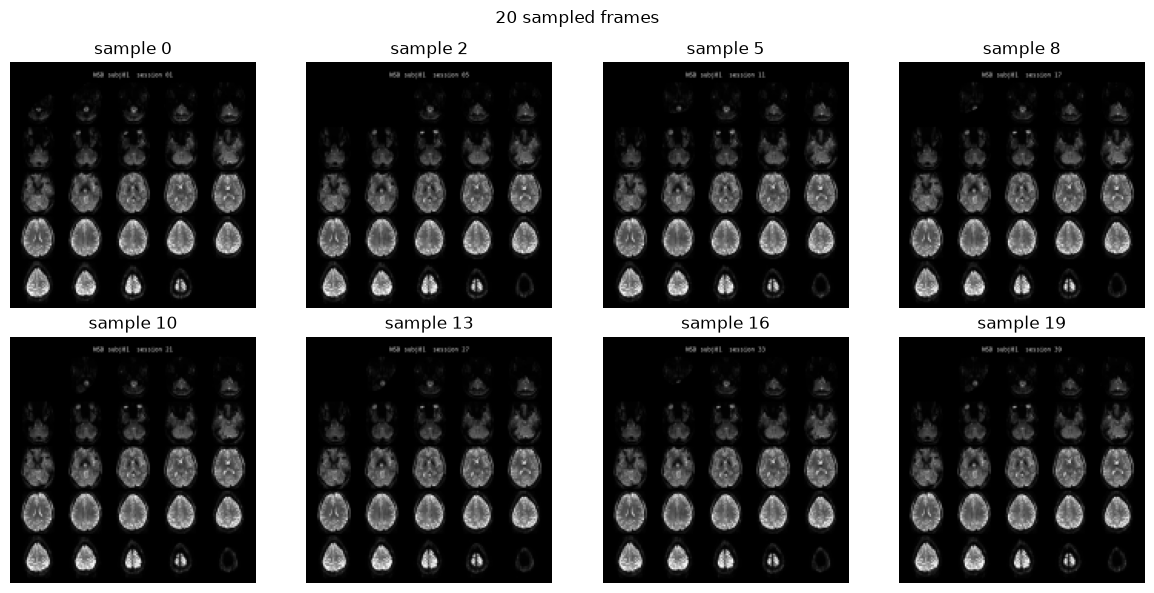

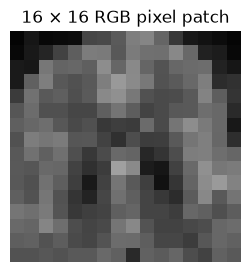

In [4]:
sample_filter = (
    "setpts=PTS-STARTPTS,trim=duration=60,"
    "select='isnan(prev_selected_t)+gte(t-prev_selected_t,0.5)',"
    "trim=end_frame=120,scale=160:160:flags=area,setsar=1,format=rgb24"
)
sampled = run([
    "ffmpeg", "-hide_banner", "-loglevel", "error", "-nostdin", "-noautorotate",
    "-i", str(VIDEO_PATH), "-map", "0:v:0", "-an", "-sn", "-dn",
    "-vf", sample_filter, "-frames:v", "120", "-fps_mode", "passthrough",
    "-pix_fmt", "rgb24", "-f", "rawvideo", "pipe:1",
])
sampled_frames = np.frombuffer(sampled.stdout, dtype=np.uint8).reshape(-1, 160, 160, 3)

frame_indices = np.linspace(0, len(sampled_frames) - 1, min(8, len(sampled_frames)), dtype=int)
figure, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis, frame_index in zip(axes.flat, frame_indices):
    axis.imshow(sampled_frames[frame_index])
    axis.set_title(f"sample {frame_index}")
    axis.axis("off")
for axis in axes.flat[len(frame_indices):]:
    axis.axis("off")
figure.suptitle(f"{len(sampled_frames)} sampled frames")
plt.tight_layout()
plt.show()

pixel_patch = sampled_frames[0, 72:88, 72:88]
plt.figure(figsize=(3, 3))
plt.imshow(pixel_patch)
plt.title("16 × 16 RGB pixel patch")
plt.axis("off")
plt.show()

## 3. Sampled visual metrics

For encoded RGB values $R,G,B \in [0,255]$, normalized luma is

$$Y = \frac{0.2126R + 0.7152G + 0.0722B}{255}.$$

- **Mean brightness**: mean $Y$ over every sampled frame and pixel.
- **Mean contrast**: population standard deviation of $Y$ within each frame, averaged across frames.
- **Mean colorfulness**: Hasler–Süsstrunk RGB-opponent score per frame, averaged across frames.
- **Mean temporal change**: mean $|Y_t-Y_{t-1}|$ at corresponding pixels in adjacent sampled frames, averaged across pairs. This is not optical flow or a cut count.

In [5]:
rgb = sampled_frames.astype(np.float64)
luma = (0.2126 * rgb[..., 0] + 0.7152 * rgb[..., 1] + 0.0722 * rgb[..., 2]) / 255.0

brightness_mean = float(luma.mean())
contrast_mean = float(luma.std(axis=(1, 2), ddof=0).mean())

red_green = rgb[..., 0] - rgb[..., 1]
yellow_blue = (rgb[..., 0] + rgb[..., 1]) / 2.0 - rgb[..., 2]
colorfulness_per_frame = (
    np.sqrt(red_green.var(axis=(1, 2)) + yellow_blue.var(axis=(1, 2)))
    + 0.3 * np.sqrt(red_green.mean(axis=(1, 2)) ** 2 + yellow_blue.mean(axis=(1, 2)) ** 2)
) / 255.0
colorfulness_mean = float(colorfulness_per_frame.mean())

temporal_change_mean = (
    float(np.abs(np.diff(luma, axis=0)).mean()) if len(luma) > 1 else None
)

visual_metrics = {
    "brightness_mean": brightness_mean,
    "contrast_mean": contrast_mean,
    "colorfulness_mean": colorfulness_mean,
    "temporal_change_mean": temporal_change_mean,
}
visual_metrics

{'brightness_mean': 0.09668149509803921,
 'contrast_mean': 0.1796231230242237,
 'colorfulness_mean': 0.0,
 'temporal_change_mean': 0.0048495468911248715}

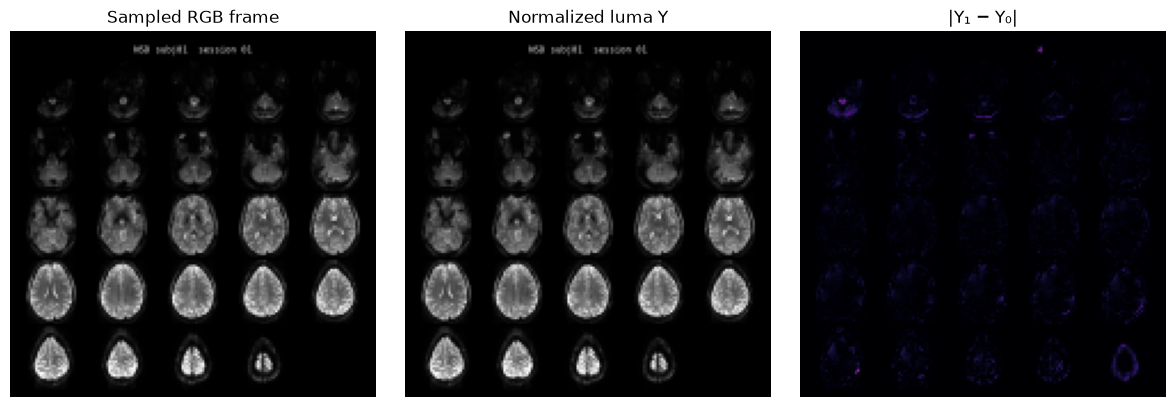

In [6]:
figure, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(sampled_frames[0])
axes[0].set_title("Sampled RGB frame")
axes[1].imshow(luma[0], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Normalized luma Y")
if len(luma) > 1:
    axes[2].imshow(np.abs(luma[1] - luma[0]), cmap="magma", vmin=0, vmax=1)
    axes[2].set_title("|Y₁ − Y₀|")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 4. Audio metrics

The first audio stream is decoded to mono, 16 kHz, signed 16-bit PCM for at most 60 seconds.

- **RMS amplitude**: $\sqrt{\frac{1}{N}\sum_i x_i^2}/32768$.
- **Silence fraction**: divide audio into non-overlapping 320-sample (20 ms) windows; mark a window silent when normalized RMS $\le 0.001$; report the sample-weighted silent fraction.

A video with no audio stream is **not measured**, not zero-volume audio. This bundled clip has no audio stream, so both results should be `None`.

In [7]:
audio_rms_amplitude = None
audio_silence_fraction = None

if audio_track_present:
    decoded_audio = run([
        "ffmpeg", "-hide_banner", "-loglevel", "error", "-nostdin",
        "-i", str(VIDEO_PATH), "-map", "0:a:0", "-vn", "-sn", "-dn",
        "-t", "60", "-ac", "1", "-ar", "16000", "-c:a", "pcm_s16le",
        "-f", "s16le", "pipe:1",
    ])
    audio_samples = np.frombuffer(decoded_audio.stdout, dtype="<i2").astype(np.float64)
    audio_rms_amplitude = float(np.sqrt(np.mean(audio_samples ** 2)) / 32768.0)

    silent_samples = 0
    for start in range(0, len(audio_samples), 320):
        window = audio_samples[start:start + 320]
        window_rms = np.sqrt(np.mean(window ** 2)) / 32768.0
        if window_rms <= 0.001:
            silent_samples += len(window)
    audio_silence_fraction = silent_samples / len(audio_samples)
else:
    print("No audio stream: audio metrics remain None (not measured).")

audio_metrics = {
    "audio_rms_amplitude": audio_rms_amplitude,
    "audio_silence_fraction": audio_silence_fraction,
}
audio_metrics

No audio stream: audio metrics remain None (not measured).


{'audio_rms_amplitude': None, 'audio_silence_fraction': None}

## 5. Hard-cut candidates

FFmpeg computes a scene-change score for every transition after resizing to width 160. A transition is counted when

$$\text{scene score} \ge 0.3.$$

The result is a count of threshold-based **candidate** cuts. It is not a semantic judgment that the event or scene changed.

In [8]:
cut_result = run([
    "ffmpeg", "-hide_banner", "-loglevel", "info", "-nostdin", "-noautorotate",
    "-i", str(VIDEO_PATH), "-map", "0:v:0", "-an", "-sn", "-dn",
    "-vf", "scale=160:-2:flags=area,format=yuv420p,select='gte(scene,0)',metadata=mode=print:key=lavfi.scene_score",
    "-fps_mode", "passthrough", "-f", "null", "pipe:1",
])
diagnostics = cut_result.stderr.decode("utf-8", "replace")
score_pattern = re.compile(r"frame:\s*(\d+)\s+pts:\s*-?\d+\s+pts_time:\s*([^\s]+).*?lavfi\.scene_score=([^\s]+)", re.S)
scene_observations = [
    (int(frame), float(seconds), float(score))
    for frame, seconds, score in score_pattern.findall(diagnostics)
]
cut_candidates = [item for item in scene_observations if item[0] > 0 and item[2] >= 0.3]
hard_cut_count = len(cut_candidates)

print({"hard_cut_count": hard_cut_count, "candidate_times_seconds": [round(x[1], 3) for x in cut_candidates]})

if cut_candidates:
    capture = cv2.VideoCapture(str(VIDEO_PATH))
    figure, axes = plt.subplots(min(3, len(cut_candidates)), 2, figsize=(8, 3 * min(3, len(cut_candidates))), squeeze=False)
    for row, (_, seconds, _) in enumerate(cut_candidates[:3]):
        for column, offset in enumerate((-0.10, 0.10)):
            capture.set(cv2.CAP_PROP_POS_MSEC, max(0, seconds + offset) * 1000)
            ok, bgr = capture.read()
            if ok:
                axes[row, column].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
            axes[row, column].set_title(f"{seconds + offset:.2f}s")
            axes[row, column].axis("off")
    capture.release()
    plt.tight_layout()
    plt.show()
else:
    print("No candidate transitions crossed the 0.3 threshold.")

{'hard_cut_count': 0, 'candidate_times_seconds': []}
No candidate transitions crossed the 0.3 threshold.


## 6. Consecutive-prefix technical metrics

These metrics use at most the first 120 consecutive frames or 10 presentation seconds, whichever comes first, resized to 160 × 160 RGB.

- **RGB chroma**: mean channel spread $(\max(R,G,B)-\min(R,G,B))/255$.
- **Near-gray fraction**: fraction of pixels whose channel spread is at most 2 encoded levels.
- **Frame-interval CV**: population standard deviation of adjacent presentation-time intervals divided by their mean.
- **Optical flow**: mean Farneback flow magnitude over all resized pixels and adjacent frame pairs, in resized pixels per pair. Cuts are not removed.

In [9]:
prefix_filter = "setpts=PTS-STARTPTS,trim=duration=10,trim=end_frame=120,scale=160:160:flags=area,setsar=1,format=rgb24"
prefix = run([
    "ffmpeg", "-hide_banner", "-loglevel", "error", "-nostdin", "-noautorotate",
    "-i", str(VIDEO_PATH), "-map", "0:v:0", "-an", "-sn", "-dn",
    "-vf", prefix_filter, "-frames:v", "120", "-fps_mode", "passthrough",
    "-pix_fmt", "rgb24", "-f", "rawvideo", "pipe:1",
])
prefix_frames = np.frombuffer(prefix.stdout, dtype=np.uint8).reshape(-1, 160, 160, 3)

timestamp_probe = run([
    "ffprobe", "-v", "error", "-select_streams", "v:0",
    "-read_intervals", "%+10", "-show_entries", "frame=best_effort_timestamp_time",
    "-of", "json", str(VIDEO_PATH),
])
timestamps = [
    float(frame["best_effort_timestamp_time"])
    for frame in json.loads(timestamp_probe.stdout).get("frames", [])[:len(prefix_frames)]
    if "best_effort_timestamp_time" in frame
]
if timestamps:
    origin = timestamps[0]
    timestamps = np.asarray([value - origin for value in timestamps], dtype=np.float64)

spread = prefix_frames.max(axis=3).astype(np.float64) - prefix_frames.min(axis=3).astype(np.float64)
rgb_chroma_mean = float(spread.mean() / 255.0)
near_gray_pixel_fraction = float((spread <= 2).mean())

intervals = np.diff(timestamps)
frame_interval_cv = float(intervals.std(ddof=0) / intervals.mean()) if len(intervals) >= 2 else None

pair_means = []
flow_magnitude_example = None
for index in range(1, len(prefix_frames)):
    previous_gray = cv2.cvtColor(prefix_frames[index - 1], cv2.COLOR_RGB2GRAY)
    current_gray = cv2.cvtColor(prefix_frames[index], cv2.COLOR_RGB2GRAY)
    flow = cv2.calcOpticalFlowFarneback(
        previous_gray, current_gray, None,
        pyr_scale=0.5, levels=3, winsize=15, iterations=3,
        poly_n=5, poly_sigma=1.2, flags=0,
    )
    magnitude = np.hypot(flow[..., 0], flow[..., 1])
    pair_means.append(float(magnitude.mean()))
    if flow_magnitude_example is None:
        flow_magnitude_example = magnitude
optical_flow_mean_px_per_pair = float(np.mean(pair_means)) if pair_means else None

technical_metrics = {
    "rgb_chroma_mean": rgb_chroma_mean,
    "near_gray_pixel_fraction": near_gray_pixel_fraction,
    "frame_interval_cv": frame_interval_cv,
    "optical_flow_mean_px_per_pair": optical_flow_mean_px_per_pair,
}
technical_metrics

{'rgb_chroma_mean': 0.0,
 'near_gray_pixel_fraction': 1.0,
 'frame_interval_cv': 0.0,
 'optical_flow_mean_px_per_pair': 0.072606432896394}

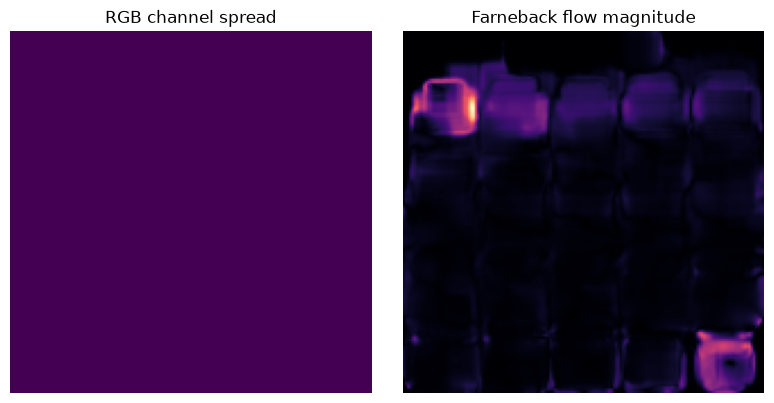

In [10]:
figure, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(spread[0], cmap="viridis", vmin=0, vmax=255)
axes[0].set_title("RGB channel spread")
if flow_magnitude_example is not None:
    axes[1].imshow(flow_magnitude_example, cmap="magma")
    axes[1].set_title("Farneback flow magnitude")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 7. On-screen text and overlaid text/logos

These are the only model-derived metrics in the current v1 plan.

Production processing uses two stages:

1. **OCR evidence proposal** scans frames for text-like regions.
2. **Qwen3-VL-8B-Instruct** receives up to eight evidence frames and assigns separate labels for added text, natural scene text, added logos, and natural scene logos.

The browser derives:

$$\text{on-screen text} = \text{added text} \lor \text{scene text}$$

$$\text{added text or watermark} = \text{added text} \lor \text{added logo}.$$

The bundled MRI montage visibly contains added session labels. To keep this notebook small and reproducible, the labels below are a **reviewed demonstration**, not a fresh Qwen inference. The production model and OCR weights are not downloaded here.

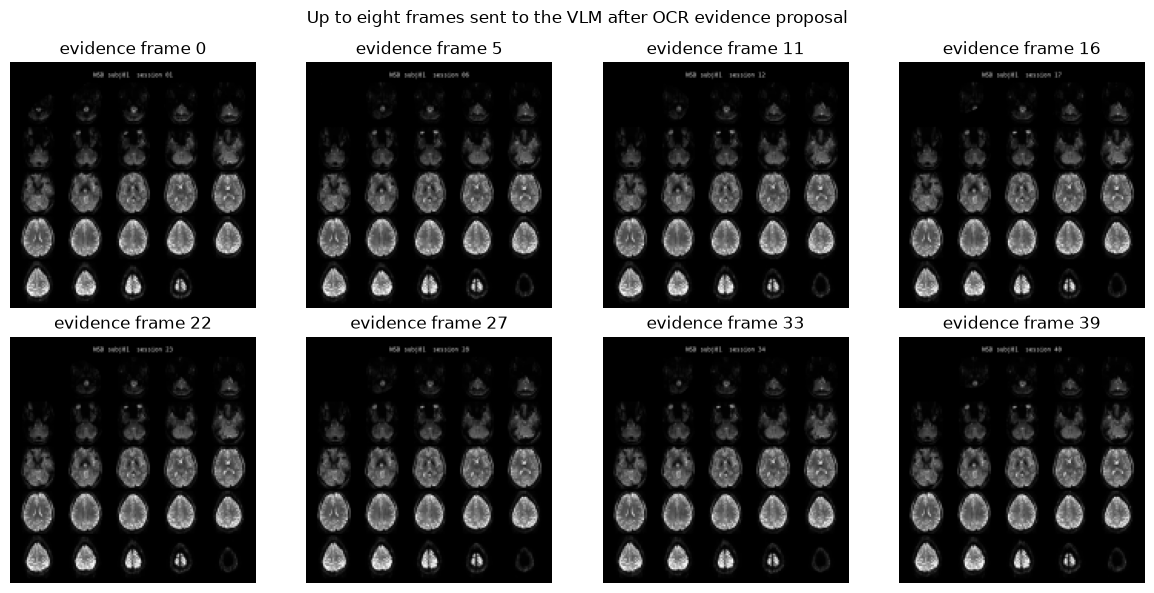

{'reviewed_component_labels': {'added_text': 'present',
  'scene_text': 'absent',
  'added_logo': 'absent',
  'scene_logo': 'absent'},
 'on_screen_text_present': True,
 'added_text_or_watermark_present': True}

In [11]:
evidence_indices = np.linspace(0, len(prefix_frames) - 1, min(8, len(prefix_frames)), dtype=int)
figure, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis, frame_index in zip(axes.flat, evidence_indices):
    axis.imshow(prefix_frames[frame_index])
    axis.set_title(f"evidence frame {frame_index}")
    axis.axis("off")
for axis in axes.flat[len(evidence_indices):]:
    axis.axis("off")
figure.suptitle("Illustrative evenly spaced prefix frames — not the production OCR-guided selection")
plt.tight_layout()
plt.show()

reviewed_labels = {
    "added_text": "present",   # session labels added during video production
    "scene_text": "absent",    # no naturally occurring text in the depicted MRI slices
    "added_logo": "absent",
    "scene_logo": "absent",
}

def tri_state_any(*labels):
    if "present" in labels:
        return True
    if labels and all(label == "absent" for label in labels):
        return False
    return None

on_screen_text_present = tri_state_any(reviewed_labels["added_text"], reviewed_labels["scene_text"])
added_text_or_watermark_present = tri_state_any(reviewed_labels["added_text"], reviewed_labels["added_logo"])

{
    "reviewed_component_labels": reviewed_labels,
    "on_screen_text_present": on_screen_text_present,
    "added_text_or_watermark_present": added_text_or_watermark_present,
}

## 8. One record for the browser

The production system also records processing status, algorithm version, and evidence. This compact dictionary shows only the values that become filterable columns.

In [12]:
metric_values = {
    **stream_metrics,
    **visual_metrics,
    **audio_metrics,
    "hard_cut_count": hard_cut_count,
    **technical_metrics,
    "on_screen_text_present": on_screen_text_present,
    "added_text_or_watermark_present": added_text_or_watermark_present,
}
metric_values

{'duration_seconds': 10.0,
 'width_px': 800,
 'height_px': 800,
 'frame_rate_fps': 4.0,
 'audio_track_present': False,
 'brightness_mean': 0.09668149509803921,
 'contrast_mean': 0.1796231230242237,
 'colorfulness_mean': 0.0,
 'temporal_change_mean': 0.0048495468911248715,
 'audio_rms_amplitude': None,
 'audio_silence_fraction': None,
 'hard_cut_count': 0,
 'rgb_chroma_mean': 0.0,
 'near_gray_pixel_fraction': 1.0,
 'frame_interval_cv': 0.0,
 'optical_flow_mean_px_per_pair': 0.072606432896394,
 'on_screen_text_present': True,
 'added_text_or_watermark_present': True}